In [29]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [30]:
%pip install datasets scikit-learn pandas numpy matplotlib torch

Note: you may need to restart the kernel to use updated packages.


DAY 53 — IMDb SENTIMENT ANALYSIS
Device: cuda

Loading IMDb dataset...
Training reviews:   21,250
Validation reviews: 3,750
Test reviews:       25,000

TRAINING NAIVE BAYES
TF-IDF vocabulary: 30000
Validation accuracy: 0.8768
Test accuracy: 0.8550
TF-IDF + NB pipeline time: 16.96s

Building neural-network vocabulary...
Neural vocabulary size: 30000
Sequence tensor: (21250, 250)
Length range: 10 to 250

Training LSTM...
LSTM | Epoch 01/8 | Train loss: 0.6197 | Train acc: 0.6386 | Val loss: 0.6709 | Val acc: 0.6725
LSTM | Epoch 02/8 | Train loss: 0.4841 | Train acc: 0.7838 | Val loss: 0.4793 | Val acc: 0.7861
LSTM | Epoch 03/8 | Train loss: 0.4003 | Train acc: 0.8328 | Val loss: 0.5599 | Val acc: 0.7744
LSTM | Epoch 04/8 | Train loss: 0.3390 | Train acc: 0.8629 | Val loss: 0.4230 | Val acc: 0.8296
LSTM | Epoch 05/8 | Train loss: 0.2766 | Train acc: 0.8950 | Val loss: 0.3926 | Val acc: 0.8416
LSTM | Epoch 06/8 | Train loss: 0.2207 | Train acc: 0.9195 | Val loss: 0.4557 | Val acc: 0.8277
L

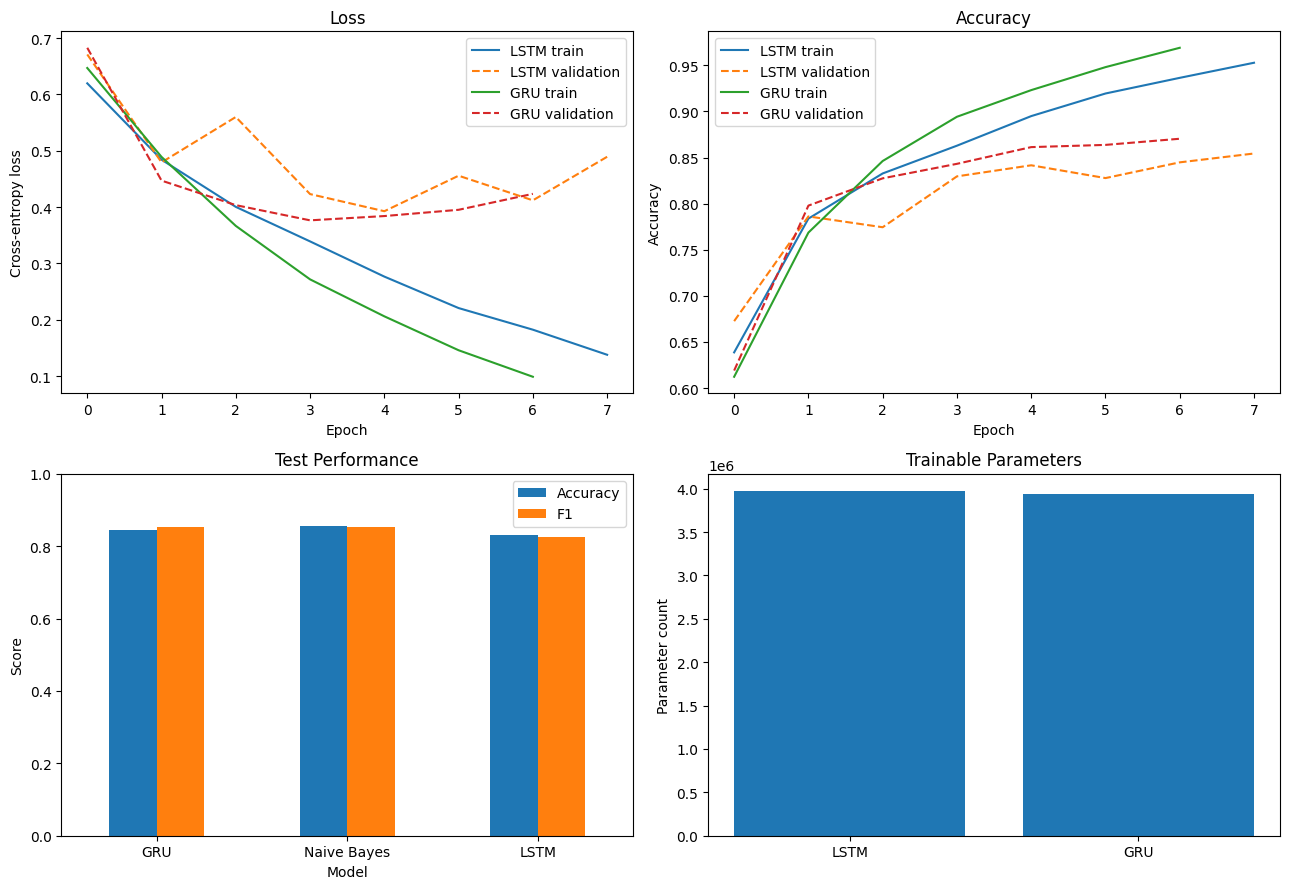


Naive Bayes — Classification Report
              precision    recall  f1-score   support

    Negative       0.84      0.87      0.86     12500
    Positive       0.87      0.84      0.85     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.85     25000
weighted avg       0.86      0.86      0.85     25000



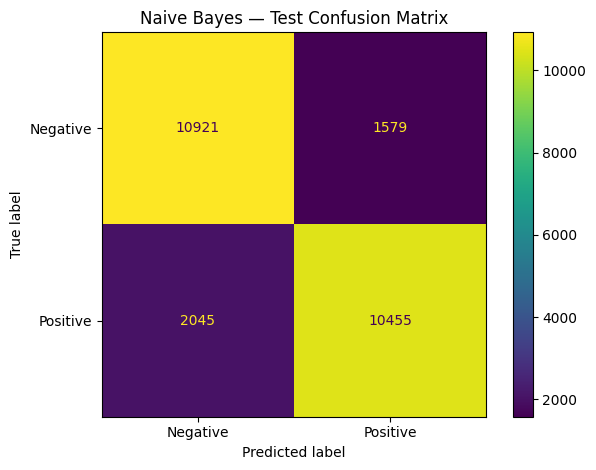


LSTM — Classification Report
              precision    recall  f1-score   support

    Negative       0.81      0.86      0.84     12500
    Positive       0.85      0.80      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



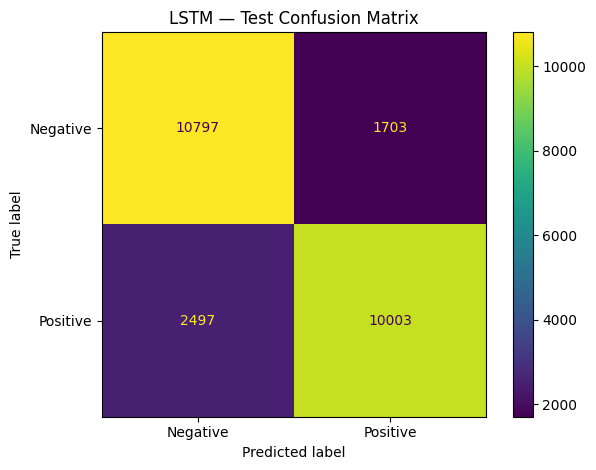


GRU — Classification Report
              precision    recall  f1-score   support

    Negative       0.89      0.78      0.83     12500
    Positive       0.81      0.90      0.85     12500

    accuracy                           0.84     25000
   macro avg       0.85      0.84      0.84     25000
weighted avg       0.85      0.84      0.84     25000



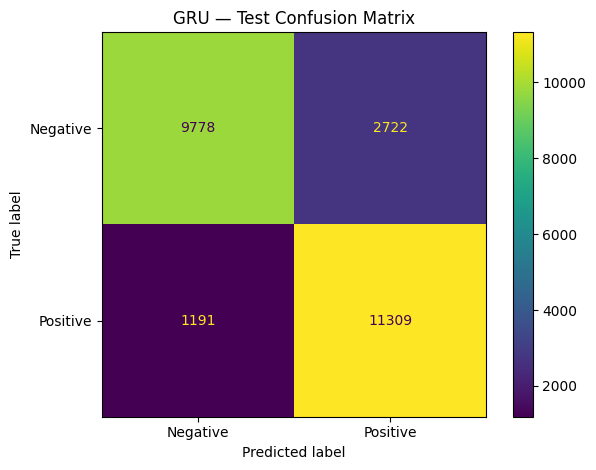


GRU misclassification examples
True: Negative
Predicted: Positive
First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this movie. Most of these movies may not have the best plots or best actors but I enjoy these kinds of movies for what they are. This movie is much better than any of the movies the other action guys (Segal and Dolph) have thought about putting out the past few years. Van Damme is good in the movie, the movie is only worth watching to Van Damme fans. It is not as good as Wake of Death (which i highly recommend to anyone of likes Van Damme) or In hell but, in my opinion it's worth watchin
-----------------------------------------------------------------
True: Negative
Predicted: Positive
Blind Date (Columbia Pictures, 1934), was a decent film, but I have a few issues with this film. First of all, I don't fault the actors in this film at all, but more or less, I have a problem with the script. Also, I understand tha

In [31]:

# ================================================================
# DAY 53/60 — END-TO-END SENTIMENT ANALYSIS
# Naive Bayes vs LSTM vs GRU
# Dataset: IMDb movie reviews
# ================================================================

import copy
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB


# ================================================================
# 1. CONFIGURATION AND REPRODUCIBILITY
# ================================================================

SEED = 42
MAX_VOCAB_SIZE = 30_000
MAX_LENGTH = 250
EMBEDDING_DIM = 128
HIDDEN_SIZE = 128
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
GRAD_CLIP = 1.0
PATIENCE = 3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 65)
print("DAY 53 — IMDb SENTIMENT ANALYSIS")
print("=" * 65)
print("Device:", device)


# ================================================================
# 2. LOAD DATA AND CREATE LEAKAGE-SAFE SPLITS
# ================================================================

print("\nLoading IMDb dataset...")

dataset = load_dataset("stanfordnlp/imdb")

all_train_texts = dataset["train"]["text"]
all_train_labels = np.asarray(
    dataset["train"]["label"], dtype=np.int64
)

test_texts = list(dataset["test"]["text"])
test_labels = np.asarray(
    dataset["test"]["label"], dtype=np.int64
)

train_texts, val_texts, train_labels, val_labels = (
    train_test_split(
        all_train_texts,
        all_train_labels,
        test_size=0.15,
        random_state=SEED,
        stratify=all_train_labels,
    )
)

train_texts = list(train_texts)
val_texts = list(val_texts)
train_labels = np.asarray(train_labels)
val_labels = np.asarray(val_labels)

print(f"Training reviews:   {len(train_texts):,}")
print(f"Validation reviews: {len(val_texts):,}")
print(f"Test reviews:       {len(test_texts):,}")


# ================================================================
# 3. NAIVE BAYES BASELINE — TF-IDF
# ================================================================

print("\n" + "=" * 65)
print("TRAINING NAIVE BAYES")
print("=" * 65)

tfidf = TfidfVectorizer(
    max_features=MAX_VOCAB_SIZE,
    ngram_range=(1, 2),
    min_df=2,
    stop_words="english",
    sublinear_tf=True,
)

start = time.perf_counter()

X_train_tfidf = tfidf.fit_transform(train_texts)
X_val_tfidf = tfidf.transform(val_texts)
X_test_tfidf = tfidf.transform(test_texts)

nb_model = MultinomialNB(alpha=0.5)
nb_model.fit(X_train_tfidf, train_labels)

nb_fit_seconds = time.perf_counter() - start

nb_val_pred = nb_model.predict(X_val_tfidf)
nb_test_pred = nb_model.predict(X_test_tfidf)

print("TF-IDF vocabulary:", len(tfidf.vocabulary_))
print(
    "Validation accuracy:",
    f"{accuracy_score(val_labels, nb_val_pred):.4f}",
)
print(
    "Test accuracy:",
    f"{accuracy_score(test_labels, nb_test_pred):.4f}",
)
print(f"TF-IDF + NB pipeline time: {nb_fit_seconds:.2f}s")


# ================================================================
# 4. BUILD VOCABULARY FROM TRAINING TEXT ONLY
# ================================================================

print("\nBuilding neural-network vocabulary...")

PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"


def tokenize(text):
    """Simple lowercase word tokenizer."""
    return re.findall(r"\b\w+\b", text.lower())


token_counts = Counter()

for text in train_texts:
    token_counts.update(tokenize(text))

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1,
}

for token, _ in token_counts.most_common(MAX_VOCAB_SIZE - 2):
    vocab[token] = len(vocab)

print("Neural vocabulary size:", len(vocab))


def encode_review(text):
    """
    Return a fixed-length token sequence and its true length.
    True length excludes padding and is at least 1.
    """
    tokens = tokenize(text)
    token_ids = [
        vocab.get(token, vocab[UNK_TOKEN])
        for token in tokens[:MAX_LENGTH]
    ]

    # Avoid zero-length sequences for empty or punctuation-only text.
    if not token_ids:
        token_ids = [vocab[UNK_TOKEN]]

    true_length = len(token_ids)

    padded_ids = token_ids + [vocab[PAD_TOKEN]] * (
        MAX_LENGTH - true_length
    )

    return padded_ids, true_length


def encode_dataset(texts):
    encoded = [encode_review(text) for text in texts]

    sequences = np.asarray(
        [item[0] for item in encoded],
        dtype=np.int64,
    )
    lengths = np.asarray(
        [item[1] for item in encoded],
        dtype=np.int64,
    )

    return sequences, lengths


X_train_seq, train_lengths = encode_dataset(train_texts)
X_val_seq, val_lengths = encode_dataset(val_texts)
X_test_seq, test_lengths = encode_dataset(test_texts)

print("Sequence tensor:", X_train_seq.shape)
print("Length range:", train_lengths.min(), "to", train_lengths.max())


# ================================================================
# 5. DATA LOADERS
# ================================================================

def make_sequence_loader(
    sequences,
    lengths,
    labels,
    shuffle=False,
):
    dataset = TensorDataset(
        torch.tensor(sequences, dtype=torch.long),
        torch.tensor(lengths, dtype=torch.long),
        torch.tensor(labels, dtype=torch.long),
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(device.type == "cuda"),
    )


train_loader = make_sequence_loader(
    X_train_seq, train_lengths, train_labels, shuffle=True
)

val_loader = make_sequence_loader(
    X_val_seq, val_lengths, val_labels
)

test_loader = make_sequence_loader(
    X_test_seq, test_lengths, test_labels
)


# ================================================================
# 6. LSTM / GRU MODEL
# ================================================================

class SentimentRNN(nn.Module):
    def __init__(
        self,
        vocab_size,
        cell_type="LSTM",
        embedding_dim=128,
        hidden_size=128,
        dropout=0.3,
    ):
        super().__init__()

        if cell_type not in {"LSTM", "GRU"}:
            raise ValueError("cell_type must be 'LSTM' or 'GRU'")

        self.cell_type = cell_type

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=0,
        )

        recurrent_class = nn.LSTM if cell_type == "LSTM" else nn.GRU

        self.recurrent = recurrent_class(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, 2)

    def forward(self, token_ids, lengths):
        # token_ids: (batch, max_sequence_length)
        embedded = self.embedding(token_ids)

        # Crucial correction:
        # recurrent computation stops at each review's true length.
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().cpu(),
            batch_first=True,
            enforce_sorted=False,
        )

        _, state = self.recurrent(packed)

        if self.cell_type == "LSTM":
            hidden_state, _ = state
        else:
            hidden_state = state

        # Final hidden state: (batch, hidden_size)
        final_hidden = hidden_state[-1]

        logits = self.classifier(self.dropout(final_hidden))

        # Return logits, not softmax probabilities.
        return logits


# ================================================================
# 7. TRAINING AND EVALUATION HELPERS
# ================================================================

criterion = nn.CrossEntropyLoss()


def evaluate_model(model, loader):
    model.eval()

    total_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for token_ids, lengths, labels in loader:
            token_ids = token_ids.to(device)
            labels = labels.to(device)

            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)

            total_loss += loss.item() * labels.size(0)

            all_predictions.extend(
                logits.argmax(dim=1).cpu().numpy()
            )
            all_labels.extend(labels.cpu().numpy())

    mean_loss = total_loss / len(all_labels)
    accuracy = accuracy_score(all_labels, all_predictions)

    return (
        mean_loss,
        accuracy,
        np.asarray(all_predictions),
        np.asarray(all_labels),
    )


def train_model(cell_type):
    # Use reproducible initialization for each model type.
    torch.manual_seed(SEED)

    model = SentimentRNN(
        vocab_size=len(vocab),
        cell_type=cell_type,
        embedding_dim=EMBEDDING_DIM,
        hidden_size=HIDDEN_SIZE,
        dropout=0.3,
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
    )

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
    }

    print(f"\nTraining {cell_type}...")

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()

        total_loss = 0.0
        total_correct = 0
        total_examples = 0

        for token_ids, lengths, labels in train_loader:
            token_ids = token_ids.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(token_ids, lengths)
            loss = criterion(logits, labels)

            loss.backward()

            # Prevent excessively large gradient updates.
            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=GRAD_CLIP,
            )

            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            total_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            total_examples += labels.size(0)

        train_loss = total_loss / total_examples
        train_accuracy = total_correct / total_examples

        val_loss, val_accuracy, _, _ = evaluate_model(
            model, val_loader
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        print(
            f"{cell_type} | Epoch {epoch + 1:02d}/{EPOCHS} | "
            f"Train loss: {train_loss:.4f} | "
            f"Train acc: {train_accuracy:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val acc: {val_accuracy:.4f}"
        )

        # Select checkpoints using validation loss only.
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch + 1}; "
                f"best validation loss: {best_val_loss:.4f}"
            )
            break

    elapsed = time.perf_counter() - start_time

    # Restore the best validation-loss checkpoint.
    model.load_state_dict(best_state)

    # Report validation metrics from the selected checkpoint.
    selected_val_loss, selected_val_acc, _, _ = evaluate_model(
        model, val_loader
    )

    print(
        f"{cell_type} selected checkpoint | "
        f"Val loss: {selected_val_loss:.4f} | "
        f"Val acc: {selected_val_acc:.4f} | "
        f"Training time: {elapsed:.1f}s"
    )

    return model, pd.DataFrame(history), elapsed


# ================================================================
# 8. TRAIN LSTM AND GRU
# ================================================================

lstm_model, lstm_history, lstm_seconds = train_model("LSTM")
gru_model, gru_history, gru_seconds = train_model("GRU")


# ================================================================
# 9. FINAL TEST EVALUATION
# Test data is not used for checkpoint selection.
# ================================================================

print("\n" + "=" * 65)
print("FINAL TEST EVALUATION")
print("=" * 65)

models = {
    "Naive Bayes": None,
    "LSTM": lstm_model,
    "GRU": gru_model,
}

test_predictions = {
    "Naive Bayes": nb_test_pred,
}

test_results = []

# Naive Bayes test predictions were calculated above.
for model_name, pred in test_predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        test_labels,
        pred,
        average="binary",
        zero_division=0,
    )

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(test_labels, pred),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

# Evaluate each selected recurrent checkpoint on the test set.
for model_name, model in [
    ("LSTM", lstm_model),
    ("GRU", gru_model),
]:
    test_loss, test_accuracy, pred, true_labels = evaluate_model(
        model, test_loader
    )

    test_predictions[model_name] = pred

    precision, recall, f1, _ = precision_recall_fscore_support(
        true_labels,
        pred,
        average="binary",
        zero_division=0,
    )

    test_results.append({
        "Model": model_name,
        "Accuracy": test_accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Test Loss": test_loss,
    })

results_df = pd.DataFrame(test_results)
results_df = results_df.sort_values(
    "F1", ascending=False
).reset_index(drop=True)

print(results_df.round(4).to_string(index=False))


# ================================================================
# 10. VISUALIZE TRAINING CURVES
# ================================================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for model_name, history in [
    ("LSTM", lstm_history),
    ("GRU", gru_history),
]:
    axes[0, 0].plot(
        history["train_loss"], label=f"{model_name} train"
    )
    axes[0, 0].plot(
        history["val_loss"], linestyle="--",
        label=f"{model_name} validation"
    )
    axes[0, 1].plot(
        history["train_accuracy"], label=f"{model_name} train"
    )
    axes[0, 1].plot(
        history["val_accuracy"], linestyle="--",
        label=f"{model_name} validation"
    )

axes[0, 0].set_title("Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Cross-entropy loss")
axes[0, 0].legend()

axes[0, 1].set_title("Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()

plot_results = results_df.set_index("Model")
plot_results[["Accuracy", "F1"]].plot(
    kind="bar", ax=axes[1, 0], ylim=(0, 1)
)
axes[1, 0].set_title("Test Performance")
axes[1, 0].set_ylabel("Score")
axes[1, 0].tick_params(axis="x", rotation=0)

parameter_counts = {}
for model_name, model in [
    ("LSTM", lstm_model),
    ("GRU", gru_model),
]:
    parameter_counts[model_name] = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

axes[1, 1].bar(
    list(parameter_counts.keys()),
    list(parameter_counts.values()),
)
axes[1, 1].set_title("Trainable Parameters")
axes[1, 1].set_ylabel("Parameter count")

plt.tight_layout()
plt.show()


# ================================================================
# 11. CLASSIFICATION REPORTS AND CONFUSION MATRICES
# ================================================================

for model_name, pred in test_predictions.items():
    print(f"\n{'=' * 60}")
    print(f"{model_name} — Classification Report")
    print("=" * 60)

    print(
        classification_report(
            test_labels,
            pred,
            target_names=["Negative", "Positive"],
            zero_division=0,
        )
    )

    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(test_labels, pred),
        display_labels=["Negative", "Positive"],
    ).plot(values_format="d")

    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()


# ================================================================
# 12. ERROR ANALYSIS — GRU EXAMPLES
# ================================================================

gru_predictions = test_predictions["GRU"]
wrong_indices = np.flatnonzero(
    test_labels != gru_predictions
)

print("\nGRU misclassification examples")
print("=" * 65)

for idx in wrong_indices[:5]:
    true_sentiment = (
        "Positive" if test_labels[idx] == 1 else "Negative"
    )
    predicted_sentiment = (
        "Positive" if gru_predictions[idx] == 1 else "Negative"
    )

    print("True:", true_sentiment)
    print("Predicted:", predicted_sentiment)
    print(test_texts[idx][:600].replace("\n", " "))
    print("-" * 65)


# ================================================================
# 13. SIMPLE INFERENCE FUNCTION
# ================================================================

def predict_sentiment(text, model=gru_model):
    """
    Predict sentiment using the selected GRU checkpoint.
    Confidence is the model's softmax score, not a guarantee.
    """
    sequence, length = encode_review(text)

    token_ids = torch.tensor(
        [sequence], dtype=torch.long, device=device
    )
    lengths = torch.tensor([length], dtype=torch.long)

    model.eval()

    with torch.no_grad():
        logits = model(token_ids, lengths)
        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_class = int(probabilities.argmax().item())

    return {
        "sentiment": (
            "Positive" if predicted_class == 1 else "Negative"
        ),
        "confidence": float(probabilities[predicted_class].item()),
        "probabilities": {
            "negative": float(probabilities[0].item()),
            "positive": float(probabilities[1].item()),
        },
    }


print("\nExample inference:")
example = (
    "The acting was excellent and the story was engaging. "
    "I thoroughly enjoyed this movie."
)
print(predict_sentiment(example))


# ================================================================
# 14. SAVE THE SELECTED MODELS AND PREPROCESSING ARTIFACTS
# ================================================================

torch.save(
    {
        "model_state_dict": gru_model.state_dict(),
        "cell_type": "GRU",
        "vocab": vocab,
        "max_length": MAX_LENGTH,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_size": HIDDEN_SIZE,
        "vocab_size": len(vocab),
        "seed": SEED,
    },
    "day53_gru_sentiment.pt",
)

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "cell_type": "LSTM",
        "vocab": vocab,
        "max_length": MAX_LENGTH,
        "embedding_dim": EMBEDDING_DIM,
        "hidden_size": HIDDEN_SIZE,
        "vocab_size": len(vocab),
        "seed": SEED,
    },
    "day53_lstm_sentiment.pt",
)

import joblib

joblib.dump(tfidf, "day53_tfidf.joblib")
joblib.dump(nb_model, "day53_naive_bayes.joblib")

print("\nSaved artifacts:")
print("- day53_gru_sentiment.pt")
print("- day53_lstm_sentiment.pt")
print("- day53_tfidf.joblib")
print("- day53_naive_bayes.joblib")

print("\nDay 53 experiment complete.")
